In [97]:
df = pd.read_csv(matches[0])

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Information:")
df.info()

Dataset Shape: (115, 19)

Column Names:
['REGION', 'YEAR', 'JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN', 'JUL', 'AUG', 'SEP', 'OCT', 'NOV', 'DEC', 'ANNUAL', 'Jan-Feb', 'Mar-May', 'Jun-Sep', 'Oct-Dec']

First 5 Records:


,REGION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,Jan-Feb,Mar-May,Jun-Sep,Oct-Dec
0,INDIA,1901,34.7,37.7,18.0,39.3,50.8,113.4,242.2,272.9,124.4,52.7,38.0,8.3,1032.3,72.4,108.1,752.8,99.0
1,INDIA,1902,7.4,4.3,19.0,43.5,48.3,108.8,284.0,199.7,201.5,61.5,27.9,24.4,1030.2,11.7,110.8,794.0,113.8
2,INDIA,1903,17.0,8.3,31.3,17.1,59.5,118.3,297.0,270.4,199.1,117.9,36.9,17.7,1190.5,25.3,107.9,884.8,172.5
3,INDIA,1904,14.4,9.6,31.8,33.1,72.4,164.8,261.0,206.4,129.6,69.0,11.2,16.3,1019.8,24.0,137.4,761.8,96.6
4,INDIA,1905,25.3,20.9,42.7,33.7,55.7,93.3,252.8,200.8,178.4,51.4,9.7,10.5,975.3,46.2,132.2,725.4,71.6



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 115 entries, 0 to 114
Data columns (total 19 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   REGION   115 non-null    str    
 1   YEAR     115 non-null    int64  
 2   JAN      115 non-null    float64
 3   FEB      115 non-null    float64
 4   MAR      115 non-null    float64
 5   APR      115 non-null    float64
 6   MAY      115 non-null    float64
 7   JUN      115 non-null    float64
 8   JUL      115 non-null    float64
 9   AUG      115 non-null    float64
 10  SEP      115 non-null    float64
 11  OCT      115 non-null    float64
 12  NOV      115 non-null    float64
 13  DEC      115 non-null    float64
 14  ANNUAL   115 non-null    float64
 15  Jan-Feb  115 non-null    float64
 16  Mar-May  115 non-null    float64
 17  Jun-Sep  115 non-null    float64
 18  Oct-Dec  115 non-null    float64
dtypes: float64(17), int64(1), str(1)
memory usage: 17.2 KB


In [98]:
# Check missing values
print("Missing Values:")
display(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Check duplicate years
print("Duplicate Years:", df["YEAR"].duplicated().sum())

# Check data types
print("\nData Types:")
print(df.dtypes)

# Check year range
print("\nYear Range:")
print(df["YEAR"].min(), "-", df["YEAR"].max())

# Check region
print("\nRegions:")
print(df["REGION"].unique())

Missing Values:


REGION     0
YEAR       0
JAN        0
FEB        0
MAR        0
APR        0
MAY        0
JUN        0
JUL        0
AUG        0
SEP        0
OCT        0
NOV        0
DEC        0
ANNUAL     0
Jan-Feb    0
Mar-May    0
Jun-Sep    0
Oct-Dec    0
dtype: int64


Duplicate Records: 0
Duplicate Years: 0

Data Types:
REGION         str
YEAR         int64
JAN        float64
FEB        float64
MAR        float64
APR        float64
MAY        float64
JUN        float64
JUL        float64
AUG        float64
SEP        float64
OCT        float64
NOV        float64
DEC        float64
ANNUAL     float64
Jan-Feb    float64
Mar-May    float64
Jun-Sep    float64
Oct-Dec    float64
dtype: object

Year Range:
1901 - 2015

Regions:
<StringArray>
['INDIA']
Length: 1, dtype: str


In [99]:
# Monthly rainfall columns
monthly_cols = [
    'JAN', 'FEB', 'MAR', 'APR',
    'MAY', 'JUN', 'JUL', 'AUG',
    'SEP', 'OCT', 'NOV', 'DEC'
]

# Calculate monthly total
df['Calculated_Annual'] = df[monthly_cols].sum(axis=1)

# Compare with given annual rainfall
df['Annual_Difference'] = (
    df['ANNUAL'] - df['Calculated_Annual']
)

print("Duplicate Records:", df.duplicated().sum())

print("\nNegative Rainfall Values:")
print((df[monthly_cols] < 0).sum().sum())

print("\nAnnual Rainfall Comparison:")
display(
    df[['YEAR', 'ANNUAL', 'Calculated_Annual',
        'Annual_Difference']].head(10)
)

Duplicate Records: 0

Negative Rainfall Values:
0

Annual Rainfall Comparison:


,YEAR,ANNUAL,Calculated_Annual,Annual_Difference
0,1901,1032.3,1032.4,-1.000000e-01
1,1902,1030.2,1030.3,-1.000000e-01
2,1903,1190.5,1190.5,-2.273737e-13
3,1904,1019.8,1019.6,2.000000e-01
4,1905,975.3,975.2,1.000000e-01
5,1906,1144.1,1144.1,0.000000e+00
6,1907,1039.7,1039.8,-1.000000e-01
7,1908,1096.6,1096.6,-2.273737e-13
8,1909,1158.1,1158.0,1.000000e-01
9,1910,1200.3,1200.4,-1.000000e-01


In [100]:
annual_diff = (
    df['ANNUAL'] - df[monthly_cols].sum(axis=1)
).round(1)

print("Maximum Difference:",
      annual_diff.abs().max())

print("Records with difference above 0.2 mm:",
      (annual_diff.abs() > 0.2).sum())

print("\nDifference Summary:")
display(annual_diff.describe())

Maximum Difference: 0.3
Records with difference above 0.2 mm: 1

Difference Summary:


count    115.000000
mean       0.006957
std        0.100631
min       -0.200000
25%        0.000000
50%        0.000000
75%        0.100000
max        0.300000
dtype: float64

In [101]:
# Identify the record with the largest annual difference

check = df.loc[
    annual_diff.abs() > 0.2,
    ['YEAR', 'ANNUAL'] + monthly_cols
].copy()

check['Calculated_Annual'] = check[monthly_cols].sum(axis=1)

check['Difference'] = (
    check['ANNUAL'] - check['Calculated_Annual']
)

display(check)

,YEAR,ANNUAL,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,Calculated_Annual,Difference
52,1953,1222.9,30.4,10.7,25.5,38.3,47.3,162.6,321.6,301.9,179.2,84.6,12.5,8.0,1222.6,0.3


In [102]:
season_cols = [
    'Jan-Feb',
    'Mar-May',
    'Jun-Sep',
    'Oct-Dec'
]

df['Calculated_Seasonal'] = df[season_cols].sum(axis=1)

df['Seasonal_Difference'] = (
    df['ANNUAL'] - df['Calculated_Seasonal']
).round(1)

print("Maximum Seasonal Difference:",
      df['Seasonal_Difference'].abs().max())

print("Records with difference above 0.2 mm:",
      (df['Seasonal_Difference'].abs() > 0.2).sum())

Maximum Seasonal Difference: 0.1
Records with difference above 0.2 mm: 0


In [103]:
from pathlib import Path

# Preserve original columns only
original_columns = [
    'REGION', 'YEAR', 'JAN', 'FEB', 'MAR',
    'APR', 'MAY', 'JUN', 'JUL', 'AUG',
    'SEP', 'OCT', 'NOV', 'DEC', 'ANNUAL',
    'Jan-Feb', 'Mar-May', 'Jun-Sep', 'Oct-Dec'
]

# Create cleaned copy
df_clean = df[original_columns].copy()

# Create Processed folder
project_folder = Path.cwd().parent

processed_folder = project_folder / "Data" / "Processed"

processed_folder.mkdir(parents=True, exist_ok=True)

# Save cleaned dataset
output_path = processed_folder / "rainfall_area_wt_India_1901_2015_clean.csv"

df_clean.to_csv(output_path, index=False)

print("Cleaned Dataset Saved Successfully!")
print("Dataset Shape:", df_clean.shape)
print("File Location:", output_path)

Cleaned Dataset Saved Successfully!
Dataset Shape: (115, 19)
File Location: c:\Users\USER\OneDrive\Desktop\Rainfall Intelligence India\Notebook\Data\Processed\rainfall_area_wt_India_1901_2015_clean.csv


In [104]:
# =====================================================
# 5. EXPLORATORY DATA ANALYSIS (EDA)
#    HISTORICAL INDIA RAINFALL (1901–2015)
# =====================================================

# Q1. Annual Rainfall Analysis

# Annual Rainfall Analysis

print("Annual Rainfall Summary:")

display(
    df_clean['ANNUAL'].describe().round(2)
)

# Wettest Year
wettest_year = df_clean.loc[
    df_clean['ANNUAL'].idxmax()
]

# Driest Year
driest_year = df_clean.loc[
    df_clean['ANNUAL'].idxmin()
]

print("\nWettest Year:")
print(wettest_year[['YEAR', 'ANNUAL']])

print("\nDriest Year:")
print(driest_year[['YEAR', 'ANNUAL']])

Annual Rainfall Summary:


count     115.00
mean     1182.03
std       110.69
min       920.80
25%      1102.40
50%      1190.50
75%      1243.55
max      1480.30
Name: ANNUAL, dtype: float64


Wettest Year:
YEAR        1917
ANNUAL    1480.3
Name: 16, dtype: object

Driest Year:
YEAR       2002
ANNUAL    920.8
Name: 101, dtype: object


In [105]:
# =====================================================
# Q2. Which month recorded the highest and lowest
#     average rainfall?
# =====================================================

# Average Monthly Rainfall Analysis

monthly_cols = [
    'JAN', 'FEB', 'MAR', 'APR',
    'MAY', 'JUN', 'JUL', 'AUG',
    'SEP', 'OCT', 'NOV', 'DEC'
]

monthly_avg = (
    df_clean[monthly_cols]
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

print("Average Monthly Rainfall (1901–2015):")

display(monthly_avg)

print("\nHighest Average Rainfall Month:")
print(monthly_avg.idxmax(), "-", monthly_avg.max(), "mm")

print("\nLowest Average Rainfall Month:")
print(monthly_avg.idxmin(), "-", monthly_avg.min(), "mm")

Average Monthly Rainfall (1901–2015):


JUL    291.02
AUG    258.40
SEP    172.47
JUN    168.36
OCT     75.70
MAY     62.19
APR     38.24
NOV     29.21
MAR     28.25
FEB     23.43
JAN     19.76
DEC     14.98
dtype: float64


Highest Average Rainfall Month:
JUL - 291.02 mm

Lowest Average Rainfall Month:
DEC - 14.98 mm


In [106]:
# =====================================================
# Q3. SEASONAL RAINFALL ANALYSIS
# =====================================================

# Select seasonal columns

season_cols = [
    'Jan-Feb',
    'Mar-May',
    'Jun-Sep',
    'Oct-Dec'
]

In [107]:
# Q3 - Step 2: Calculate Average Seasonal Rainfall

season_avg = df[season_cols].mean().round(2)

print("Average Seasonal Rainfall (1901–2015):")
display(season_avg)

Average Seasonal Rainfall (1901–2015):


Jan-Feb     43.19
Mar-May    128.69
Jun-Sep    890.26
Oct-Dec    119.88
dtype: float64

In [108]:
# Q3 - Step 3: Calculate Seasonal Contribution Percentage

season_contribution = (
    df[season_cols].sum() / df['ANNUAL'].sum() * 100
).round(2)

print("Seasonal Contribution Percentage (1901–2015):")
display(season_contribution)

Seasonal Contribution Percentage (1901–2015):


Jan-Feb     3.65
Mar-May    10.89
Jun-Sep    75.32
Oct-Dec    10.14
dtype: float64

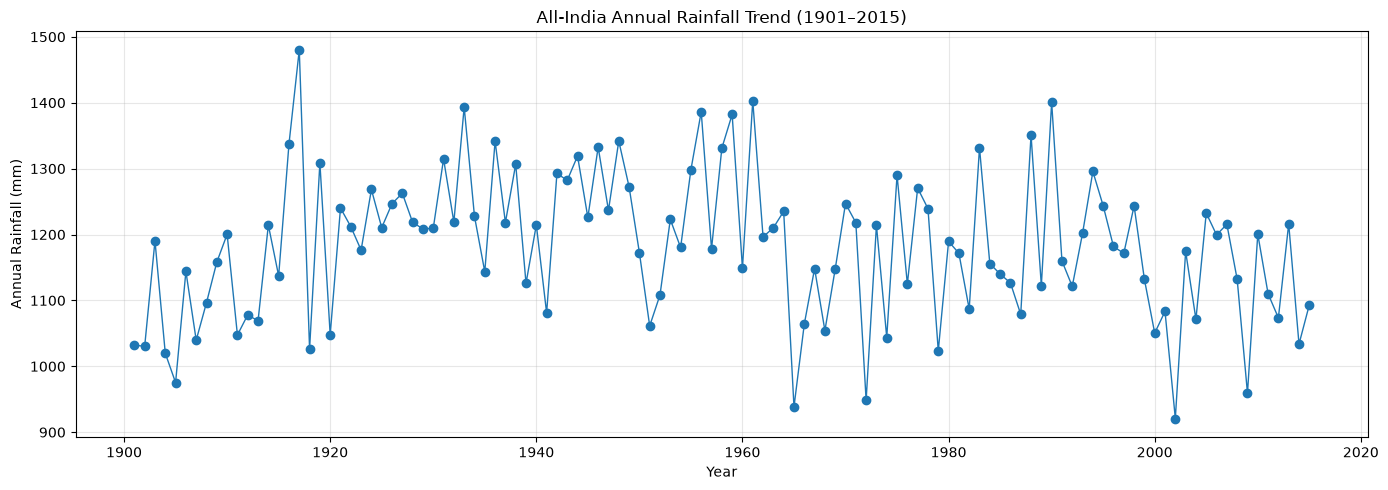

In [109]:
# =====================================================
# Q4. LONG-TERM ANNUAL RAINFALL TREND
# =====================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    df['YEAR'],
    df['ANNUAL'],
    marker='o',
    linewidth=1
)

plt.title('All-India Annual Rainfall Trend (1901–2015)')
plt.xlabel('Year')
plt.ylabel('Annual Rainfall (mm)')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [110]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [111]:
# =====================================================
# Q5. DECADE-WISE AVERAGE RAINFALL
# =====================================================

decade_df = df[['YEAR', 'ANNUAL']].copy()

decade_df['Decade'] = ((decade_df['YEAR'] - 1) // 10) * 10 + 1

decade_avg = decade_df.groupby('Decade')['ANNUAL'].mean().round(2)

print("Decade-wise Average Annual Rainfall (mm):")
display(decade_avg)

Decade-wise Average Annual Rainfall (mm):


Decade
1901    1088.69
1911    1174.64
1921    1225.28
1931    1250.50
1941    1255.66
1951    1229.75
1961    1164.43
1971    1156.18
1981    1196.53
1991    1180.14
2001    1118.93
2011    1105.34
Name: ANNUAL, dtype: float64

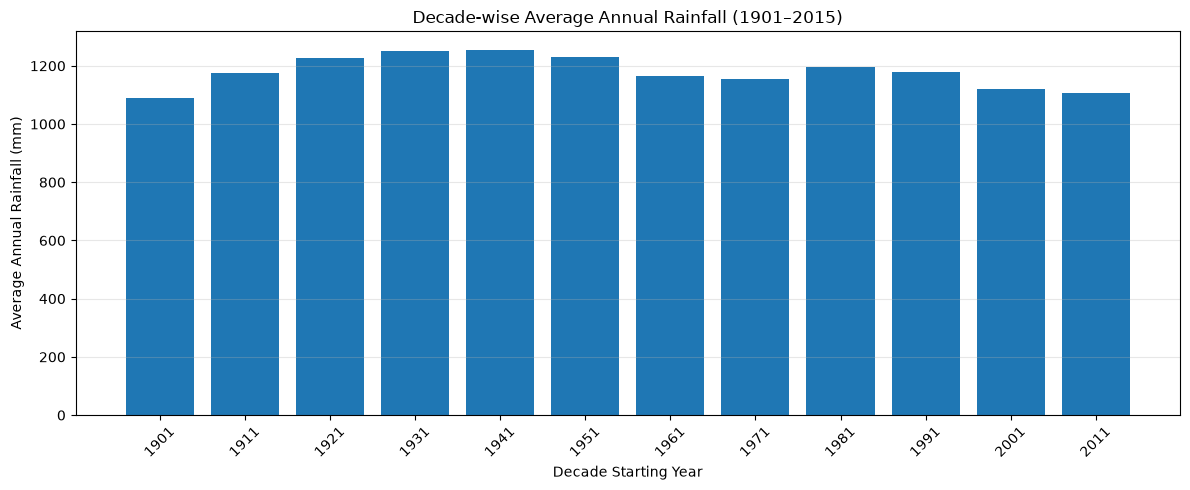

In [112]:
# Q5 - Step 2: Visualize Decade-wise Average Rainfall

plt.figure(figsize=(12, 5))

plt.bar(decade_avg.index.astype(str), decade_avg.values)

plt.title('Decade-wise Average Annual Rainfall (1901–2015)')
plt.xlabel('Decade Starting Year')
plt.ylabel('Average Annual Rainfall (mm)')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()